#Title: Email / SMS Spam Detection Using Machine Learning

Platform: Google Colab

Language: Python

Libraries: pandas, NumPy, scikit-learn, Matplotlib, Seaborn
1. Project overview
This project builds a text-classification model that predicts whether a short message is spam or ham (genuine/not spam). It uses the SMS Spam Collection dataset, TF-IDF text features, and a Multinomial Naive Bayes classifier.
Note: The commonly used public dataset contains SMS messages rather than full email bodies. The same text-classification workflow can be adapted to email datasets.

2. Problem statement
Unwanted messages can contain advertisements, scams, or suspicious links. Manually checking every message takes time. The goal is to train a machine-learning model that automatically classifies a message as spam or ham.

3. Objectives
- Load and understand a labelled message dataset.
- Clean and transform text into numerical features.
- Train a Naive Bayes classification model.
- Evaluate performance using accuracy, precision, recall, F1-score, and a confusion matrix.
- Test the model with new user-entered messages.

#5. Import required libraries

In [1]:
import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

#6. Download and load the dataset

In [2]:
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as z:
    # The archive contains a file named SMSSpamCollection.
    data_file = next(name for name in z.namelist() if name.endswith("SMSSpamCollection"))
    with z.open(data_file) as f:
        df = pd.read_csv(
            f,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


#7. Explore the dataset

In [3]:
print("Dataset shape:", df.shape)
print("\\nMissing values:")
print(df.isnull().sum())
print("\\nLabel counts:")
print(df["label"].value_counts())
print("\\nDataset information:")
df.info()

Dataset shape: (5572, 2)
\nMissing values:
label      0
message    0
dtype: int64
\nLabel counts:
label
ham     4825
spam     747
Name: count, dtype: int64
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


#8. Visualize class distribution

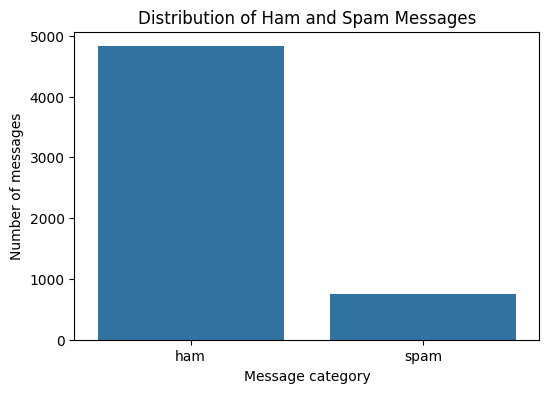

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label")
plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message category")
plt.ylabel("Number of messages")
plt.show()

#9. Prepare the data
Convert labels to readable categories, remove empty rows, and split the data into training and testing sets. A stratified split keeps approximately the same spam/ham proportion in both sets.

In [5]:
df = df.dropna(subset=["label", "message"]).copy()
df["label"] = df["label"].str.lower().str.strip()
df["message"] = df["message"].astype(str)
df = df[df["label"].isin(["ham", "spam"])]

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 4457
Testing examples: 1115


#10. Build the machine-learning pipeline
TF-IDF converts text into numerical features. It gives more weight to words that are useful for distinguishing messages while reducing the influence of very common words.

Multinomial Naive Bayes is a simple and effective baseline algorithm for text classification.

Using a pipeline ensures the vectorizer is fitted only on training messages, helping prevent data leakage.

In [6]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=1
    )),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


#11. Make predictions

In [7]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Message": X_test.values
})
results.head(10)

,Actual,Predicted,Message
0,ham,ham,No need to buy lunch for me.. I eat maggi mee..
1,ham,ham,Ok im not sure what time i finish tomorrow but...
2,ham,ham,Waiting in e car 4 my mum lor. U leh? Reach ho...
3,spam,spam,"You have won ?1,000 cash or a ?2,000 prize! To..."
4,ham,ham,If you r @ home then come down within 5 min
5,ham,ham,No need lar. Jus testing e phone card. Dunno n...
6,ham,ham,Wot about on wed nite I am 3 then but only til 9!
7,ham,ham,Hey you gave them your photo when you register...
8,ham,ham,"Hello, my boytoy! I made it home and my consta..."
9,ham,ham,Eh u remember how 2 spell his name... Yes i di...


#12. Evaluate the model

In [8]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="spam")
recall = recall_score(y_test, y_pred, pos_label="spam")
f1 = f1_score(y_test, y_pred, pos_label="spam")

print(f"Accuracy : {accuracy:.4f}")
print(f"Spam precision: {precision:.4f}")
print(f"Spam recall   : {recall:.4f}")
print(f"Spam F1-score : {f1:.4f}")
print("\\nClassification report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.9623
Spam precision: 1.0000
Spam recall   : 0.7181
Spam F1-score : 0.8359
\nClassification report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.72      0.84       149

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



#13. Confusion matrix

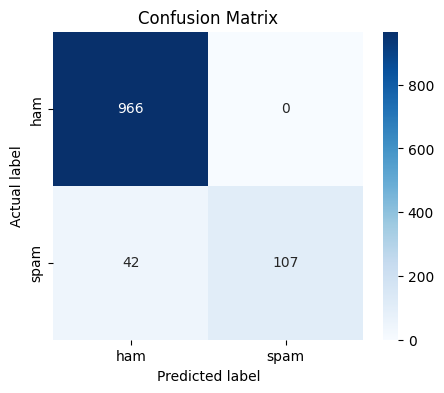

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix")
plt.show()

#14. Test the model with your own message

In [10]:
def predict_message(message):
    prediction = model.predict([message])[0]
    probabilities = model.predict_proba([message])[0]
    class_probabilities = dict(zip(model.classes_, probabilities))

    print("Message:", message)
    print("Prediction:", "SPAM" if prediction == "spam" else "HAM (Genuine)")
    print(f"Spam probability: {class_probabilities['spam']:.2%}")
    print(f"Ham probability : {class_probabilities['ham']:.2%}")

# Try changing this message.
predict_message("Congratulations! You have won a free prize. Click this link now.")

Message: Congratulations! You have won a free prize. Click this link now.
Prediction: SPAM
Spam probability: 60.84%
Ham probability : 39.16%


#15. Try multiple sample messages

In [11]:
sample_messages = [
    "Hey, are we still meeting for lunch today?",
    "URGENT! You have won a free gift card. Claim now!",
    "Please send me the class notes when you get time.",
    "You have been selected for a cash reward. Call now!"
]

for message in sample_messages:
    predict_message(message)
    print("-" * 60)

Message: Hey, are we still meeting for lunch today?
Prediction: HAM (Genuine)
Spam probability: 0.53%
Ham probability : 99.47%
------------------------------------------------------------
Message: URGENT! You have won a free gift card. Claim now!
Prediction: SPAM
Spam probability: 56.64%
Ham probability : 43.36%
------------------------------------------------------------
Message: Please send me the class notes when you get time.
Prediction: HAM (Genuine)
Spam probability: 1.93%
Ham probability : 98.07%
------------------------------------------------------------
Message: You have been selected for a cash reward. Call now!
Prediction: SPAM
Spam probability: 57.38%
Ham probability : 42.62%
------------------------------------------------------------


#16. Save the trained model
This saves the complete pipeline, including TF-IDF and the classifier. Download the file from the Colab Files panel if you want to keep it.

In [12]:
import joblib

joblib.dump(model, "spam_detection_model.joblib")
print("Saved as spam_detection_model.joblib")

Saved as spam_detection_model.joblib


#17. Conclusion
This project demonstrates a complete beginner-to-intermediate machine-learning workflow for text classification. The model uses TF-IDF and Multinomial Naive Bayes to classify messages as spam or ham. Evaluation metrics and a confusion matrix help assess its performance.

Limitations: The model learns patterns from the dataset and may make mistakes on new, unusual, multilingual, or deliberately disguised messages. It is a learning prototype, not a production email-security filter.

#18. Future enhancements
- Train on a larger email-specific dataset.
- Compare Naive Bayes with Logistic Regression and Support Vector Machines.
- Add a simple Streamlit web interface.
- Add email subject and sender-related features when a suitable dataset is available.
- Test against newly collected and diverse messages.

#19. References
- UCI Machine Learning Repository: SMS Spam Collection
  https://archive.ics.uci.edu/dataset/228/sms+spam+collection
- scikit-learn documentation: https://scikit-learn.org/stable/
- pandas documentation: https://pandas.pydata.org/docs/